# TelcoTriage — Exploratory Data Analysis

## Task #1: Initial Data Exploration

### Objective
Conduct initial exploratory data analysis (EDA) on the provided labeled
customer-support dataset to:

- Examine dataset size and structure
- Identify column data types and formats
- Analyze missing values
- Check for duplicate records
- Examine label distribution
- Document fields relevant to the NLP classification task

In [67]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the main preprocessing/training dataset from the project GitHub repository
url = "https://raw.githubusercontent.com/Break-Through-Tech/Telecom-1A-automated-telecom-support-nlp-agent-for-incident-management/main/data/twcs_filtered_labeled_1.csv"

df = pd.read_csv(url)

# Preview the first five rows to understand the structure of the dataset
# and verify that the CSV loaded correctly.
df.head()

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,label
0,2,115712.0,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1.0,General / Other
1,3,115712.0,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messag...,1,4.0,General / Other
2,5,115712.0,True,Tue Oct 31 21:49:35 +0000 2017,@sprintcare I did.,4,6.0,General / Other
3,8,115712.0,True,Tue Oct 31 21:45:10 +0000 2017,@sprintcare is the worst customer service,"9,6,10",NaN,General / Other
4,12,115713.0,True,Tue Oct 31 22:04:47 +0000 2017,@sprintcare You gonna magically change your co...,"11,13,14",15.0,General / Other


In [68]:
# Check the dimensions of the dataset
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display all column names to identify the information available
# for each tweet and determine which fields may be useful for classification
print("\nColumns:")
print(df.columns.tolist())

# The dataset contains 76404 tweet records (rows) and 8 original fields (columns).

Dataset shape: (76404, 8)
Number of rows: 76404
Number of columns: 8

Columns:
['tweet_id', 'author_id', 'inbound', 'created_at', 'text', 'response_tweet_id', 'in_response_to_tweet_id', 'label']


In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76404 entries, 0 to 76403
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   tweet_id                 76404 non-null  object 
 1   author_id                76400 non-null  float64
 2   inbound                  76400 non-null  object 
 3   created_at               76396 non-null  object 
 4   text                     76396 non-null  object 
 5   response_tweet_id        58589 non-null  object 
 6   in_response_to_tweet_id  51394 non-null  float64
 7   label                    76404 non-null  object 
dtypes: float64(2), object(6)
memory usage: 4.7+ MB


## Missing Values Analysis


In [70]:
# This identifies columns that may require cleaning or exclusion
# before model development
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_values

,Missing Count,Missing Percentage
tweet_id,0,0.00
author_id,4,0.01
inbound,4,0.01
created_at,8,0.01
text,8,0.01
response_tweet_id,17815,23.32
in_response_to_tweet_id,25010,32.73
label,0,0.00


## Task #1: Initial Data Exploration

### Dataset Overview

The `twcs_filtered_labeled_1.csv` dataset was loaded from the project's GitHub repository using Pandas. Initial exploratory data analysis (EDA) was conducted to understand the dataset's structure, data types, missing values, and fields relevant to the NLP classification task.

### Initial Findings

- The dataset contains **76,404 tweet records** and **8 original fields**.
- The available fields are:
  - `tweet_id`
  - `author_id`
  - `inbound`
  - `created_at`
  - `text`
  - `response_tweet_id`
  - `in_response_to_tweet_id`
  - `label`

- `tweet_id`, `inbound`, `created_at`, `text`, `response_tweet_id`, and `label` are currently stored as `object` fields.
- `author_id` and `in_response_to_tweet_id` are stored as `float64`.
- `created_at` is currently stored as an object/string rather than a datetime data type.
- `label` is complete, with **0 missing values** across all 76,404 records.
- `text` contains **8 missing values (0.01%)**.
- `author_id` and `inbound` each contain **4 missing values (0.01%)**.
- `created_at` contains **8 missing values (0.01%)**.
- `response_tweet_id` contains **17,815 missing values (23.32%)**.
- `in_response_to_tweet_id` contains **25,010 missing values (32.73%)**.

The missing values in `text` are especially relevant because tweet text is expected to serve as the primary input to the NLP classifier. These records should be addressed during preprocessing before model training.

### Fields Relevant to Classification

| Field | Relevance to Classification |
|---|---|
| `tweet_id` | Identifier for each tweet. Useful for record tracking, but not intended as a predictive feature. |
| `author_id` | Identifies the tweet author. Useful as metadata but not currently intended as a primary classification feature. |
| `inbound` | Indicates whether a tweet is an incoming message. May be useful for distinguishing customer tweets from company responses. |
| `created_at` | Timestamp associated with the tweet. Useful for temporal/contextual analysis but not currently planned as a primary NLP feature. |
| `text` | **Primary input feature (X)** containing the customer-support message to be classified. |
| `response_tweet_id` | Identifies responses associated with a tweet. Contains 23.32% missing values and is not currently planned as a primary text-classification feature. |
| `in_response_to_tweet_id` | Identifies the tweet to which a message responds. Contains 32.73% missing values and may provide conversation context but is not currently planned as a primary classifier feature. |
| `label` | **Target variable (y)** representing the support category the model will learn to predict. |

### Conclusion

The training dataset contains **76,404 labeled customer-support tweets**. The `text` field will serve as the primary input for the initial NLP classifier, while `label` will serve as the prediction target.

The target labels are complete, but a small number of records contain missing tweet text and other metadata. The response-related columns also contain substantial missing data. These findings should be considered during later preprocessing rather than automatically removing records or columns during initial EDA.


## Task #2: Label and Dataset Quality Analysis

### Objective

Analyze the existing classification labels and overall dataset quality by:

- Identifying the available classification labels
- Checking for missing labels
- Calculating class counts and percentages
- Visualizing the class distribution
- Identifying potential class imbalance
- Checking for duplicate or malformed records

In [71]:
# Examine the unique classification labels in the dataset
print("Number of unique labels:", df["label"].nunique())

print("\nLabels:")
print(df["label"].unique())

# The dataset currently contains 6 classification categories,
# including General / Other and the 5 target support categories.

Number of unique labels: 6

Labels:
['General / Other' 'Account & Plan Management'
 'Device & Technical Support' 'Network & Connectivity' 'Billing & Payment'
 'Cancellation & Retention']


In [72]:
# Count the number of records assigned to each category
label_counts = df["label"].value_counts()

label_counts

,count
label,
General / Other,52476
Device & Technical Support,10387
Network & Connectivity,6085
Billing & Payment,3088
Account & Plan Management,2619
Cancellation & Retention,1749


In [73]:
# Calculate the count and percentage of records in each classification category
label_distribution = pd.DataFrame({
    "Count": df["label"].value_counts(),
    "Percentage": (df["label"].value_counts(normalize=True) * 100).round(2)
})

label_distribution

,Count,Percentage
label,,
General / Other,52476,68.68
Device & Technical Support,10387,13.59
Network & Connectivity,6085,7.96
Billing & Payment,3088,4.04
Account & Plan Management,2619,3.43
Cancellation & Retention,1749,2.29


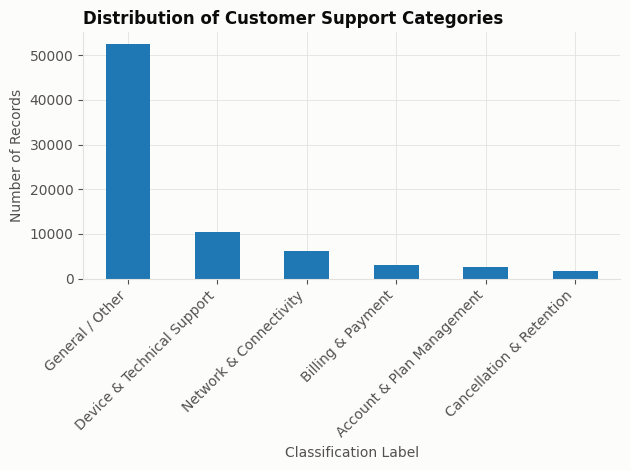

In [74]:
# Visualize the number of tweets in each classification category
df["label"].value_counts().plot(kind="bar")

plt.title("Distribution of Customer Support Categories")
plt.xlabel("Classification Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Label Distribution Findings

- The dataset contains **6 classification labels** and **0 missing target labels**.
- `General / Other` is the dominant category with **52,476 records (68.68%)**.
- The remaining five categories are the target support categories for the final classifier.
- Among the five target categories, `Device & Technical Support` is the largest with **10,387 records**, while `Cancellation & Retention` is the smallest with **1,749 records**.
- The current six-class dataset is **strongly imbalanced**.
- The project plan specifies removing `General / Other` before modeling.
- After removing `General / Other`, the remaining five classes should be analyzed again because they are still not equally represented.

In [75]:
# Count repeated non-missing tweet text
duplicate_text_count = df.loc[df["text"].notna(), "text"].duplicated().sum()

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate tweet IDs:", df["tweet_id"].duplicated().sum())
print("Duplicate non-missing tweet text:", duplicate_text_count)

Duplicate rows: 0
Duplicate tweet IDs: 1
Duplicate non-missing tweet text: 2539


### Duplicate and Record Quality Analysis

- No completely duplicated rows were identified.
- One duplicated value was detected in the `tweet_id` field.
- Inspection showed that the duplicated value was `#UnhappySpectrumCharterCustomer`, which does not appear to be a valid tweet identifier.
- The affected records contain missing or misaligned fields, suggesting malformed records rather than legitimate duplicate tweet IDs.
- **2,539 repeated non-missing tweet-text entries** were identified.
- Repeated text should not automatically be treated as duplicate data because different customers may submit identical or very similar messages.
- These repeated records should be investigated before deciding whether any should be removed during preprocessing.

In [76]:
# Inspect records with duplicated tweet IDs
duplicate_ids = df[df["tweet_id"].duplicated(keep=False)]
duplicate_ids

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,label
33803,#UnhappySpectrumCharterCustomer,NaN,1425074.0,NaN,NaN,NaN,NaN,General / Other
51185,#UnhappySpectrumCharterCustomer,NaN,1985267.0,NaN,NaN,NaN,NaN,General / Other


In [77]:
# Inspect examples where the same non-missing tweet text occurs more than once
duplicate_text = df[
    df["text"].notna() &
    df["text"].duplicated(keep=False)
].sort_values("text")

duplicate_text[["tweet_id", "author_id", "text", "label"]].head(20)

,tweet_id,author_id,text,label
14902,710173,289812.0,. @115955 @Ask_Spectrum is officially worse th...,General / Other
54213,2054142,607525.0,. @115955 @Ask_Spectrum is officially worse th...,General / Other
15016,713602,175737.0,@115714 @sprintcare,General / Other
17834,824918,316466.0,@115714 @sprintcare,General / Other
23436,1055072,369300.0,@115714 @sprintcare,General / Other
5636,289415,184973.0,@115714 @sprintcare,General / Other
55688,2083069,439210.0,@115714 @sprintcare,General / Other
73228,2865018,795773.0,@115714 @sprintcare,General / Other
32554,1379221,441101.0,@115714 @sprintcare,General / Other
59471,2257175,518784.0,@115722 @VerizonSupport,General / Other


### Task #2 Conclusion

The dataset contains **6 classification labels with no missing target labels**. The class distribution is highly imbalanced, with `General / Other` representing **52,476 records (68.68%)**.

The project intends to remove `General / Other` and retain the five target support categories. After filtering, the class distribution should be recalculated to determine the remaining imbalance and whether class weighting or resampling should be considered during model development.

The data-quality analysis also identified **no completely duplicated rows, one malformed duplicated `tweet_id` value, and 2,539 repeated non-missing text entries**. These findings should be investigated and handled during preprocessing rather than automatically removed during EDA.

In [78]:
import html
import re

# The 5 target categories (General / Other is dropped per the project plan)
TARGET_LABELS = [
    "Account & Plan Management",
    "Billing & Payment",
    "Cancellation & Retention",
    "Device & Technical Support",
    "Network & Connectivity",
]

print("Starting rows:", len(df))

# Malformed records (e.g. '#UnhappySpectrumCharterCustomer') have a non-numeric tweet_id
df_filtered = df[df["tweet_id"].astype(str).str.fullmatch(r"\d+")]

# Drop rows with missing text
df_filtered = df_filtered[df_filtered["text"].notna()]

# Remove General / Other and keep the 5 target classes
df_filtered = df_filtered[df_filtered["label"].isin(TARGET_LABELS)].reset_index(drop=True)

print("After filtering:", len(df_filtered))

Starting rows: 76404
After filtering: 23928


,Count,Percentage
label,,
Device & Technical Support,10387,43.41
Network & Connectivity,6085,25.43
Billing & Payment,3088,12.91
Account & Plan Management,2619,10.95
Cancellation & Retention,1749,7.31


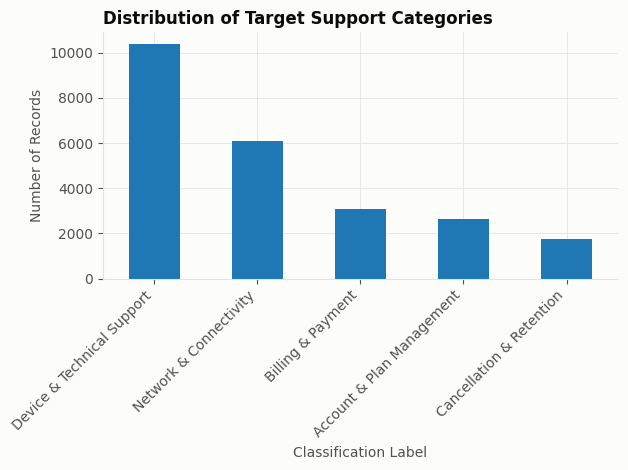

In [79]:
label_distribution = pd.DataFrame({
    "Count": df_filtered["label"].value_counts(),
    "Percentage": (df_filtered["label"].value_counts(normalize=True) * 100).round(2)
})
display(label_distribution)

df_filtered["label"].value_counts().plot(kind="bar")
plt.title("Distribution of Target Support Categories")
plt.xlabel("Classification Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [80]:
MENTION_RE = re.compile(r"@\w+")
URL_RE = re.compile(r"(?:https?://|www\.)\S+", flags=re.IGNORECASE)
APOSTROPHE_RE = re.compile(r"['\u2019\u2018`]")
NON_ALNUM_RE = re.compile(r"[^a-z0-9\s]")
WS_RE = re.compile(r"\s+")

def clean_text(text):
    text = html.unescape(text)          # &amp; -> &, &lt; -> <
    text = URL_RE.sub(" ", text)        # remove t.co and other links
    text = MENTION_RE.sub(" ", text)    # remove @mentions
    text = text.lower()
    text = APOSTROPHE_RE.sub("", text)  # don't -> dont, keeps contractions as one token
    text = NON_ALNUM_RE.sub(" ", text)  # drop punctuation and special characters
    return WS_RE.sub(" ", text).strip()

In [81]:
df_clean = df_filtered.copy()
df_clean["text_original"] = df_clean["text"]
df_clean["text_clean"] = df_clean["text"].map(clean_text)
df_clean = df_clean.drop(columns=["text"])

# Drop any tweets that were only mentions, links or punctuation
df_clean = df_clean[df_clean["text_clean"].str.len() > 0].reset_index(drop=True)

print("Final rows:", len(df_clean))
df_clean[["text_original", "text_clean", "label"]].sample(8, random_state=1)

Final rows: 23928


,text_original,text_clean,label
16030,@Ask_Spectrum hey when are you guys gonna get ...,hey when are you guys gonna get a fire stick app,Device & Technical Support
10350,@VerizonSupport Yes I am. I've spent over thre...,yes i am ive spent over three hours on the pon...,Account & Plan Management
19290,@144529 @115911 @TMobileHelp i would like to u...,i would like to use the 5 atom promo however t...,Device & Technical Support
20040,@ATT @717242 I have tried restarting my device...,i have tried restarting my device and still do...,Device & Technical Support
8119,@VerizonSupport I used to get 80 down 50 up,i used to get 80 down 50 up,Network & Connectivity
22863,Just got off the phone with @Ask_Spectrum @115...,just got off the phone with and was quoted a d...,Device & Technical Support
22848,@TMobileHelp how’s the $0 down for all promoti...,hows the 0 down for all promotion work,Network & Connectivity
993,@sprintcare we have major issues. I stopped be...,we have major issues i stopped being a custome...,Billing & Payment


In [82]:
df_clean.to_csv("twcs_cleaned.csv", index=False)

Task #5:

In [83]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# Fixed class order and one color per class, so every chart uses the same colors
CLASS_ORDER = [
    "Device & Technical Support",
    "Network & Connectivity",
    "Billing & Payment",
    "Account & Plan Management",
    "Cancellation & Retention",
]
CLASS_COLORS = dict(zip(CLASS_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))

# Short names for chart labels
SHORT = {
    "Device & Technical Support": "Device/Tech Support",
    "Network & Connectivity": "Network",
    "Billing & Payment": "Billing/Payment",
    "Account & Plan Management": "Account/Plan",
    "Cancellation & Retention": "Cancellation",
}

# Chart styling (light background, light grid, no top/right borders)
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e3e2de"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Task #5: Class Labels and Class Imbalance
Objective
Confirm the five target labels, measure the class imbalance after removing General / Other, check how the labels relate to the tweet text, and decide whether to use class weights or resampling.

In [84]:
# Class counts after dropping General / Other, in a fixed order
counts = df_clean["label"].value_counts().reindex(CLASS_ORDER)

# Percentage of the dataset, and how many times smaller each class is than the largest
dist = pd.DataFrame({"Count": counts, "Percentage": (counts / counts.sum() * 100).round(2)})
dist["Times smaller than largest"] = (counts.max() / counts).round(1)
display(dist)

print(f"Imbalance ratio (largest / smallest): {counts.max() / counts.min():.1f} : 1")

,Count,Percentage,Times smaller than largest
label,,,
Device & Technical Support,10387,43.41,1.0
Network & Connectivity,6085,25.43,1.7
Billing & Payment,3088,12.91,3.4
Account & Plan Management,2619,10.95,4.0
Cancellation & Retention,1749,7.31,5.9


Imbalance ratio (largest / smallest): 5.9 : 1


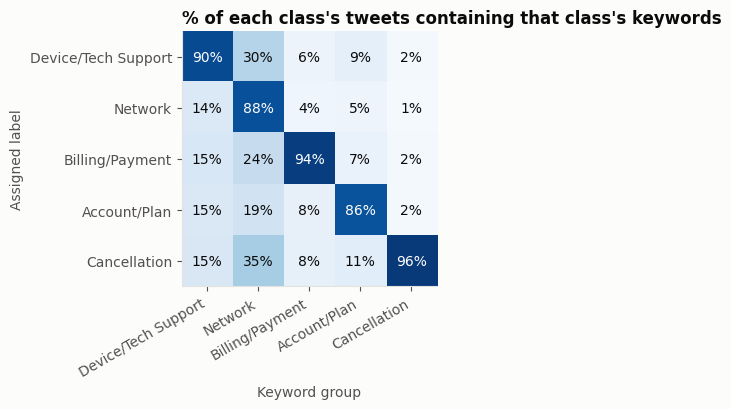

In [85]:
# For each class, what share of its tweets contain keywords from each category?
# If every class mostly matches only its own keywords, the labels were likely assigned by keyword rules.
KEYWORDS = {
    "Billing & Payment": r"bill|charge|pay|refund|credit|fee|price|autopay|invoice",
    "Network & Connectivity": r"signal|network|coverage|outage|service|slow|speed|data|internet|wifi|connect|lte|4g",
    "Cancellation & Retention": r"cancel|switch|leav|disconnect|terminate|close my|quit",
    "Account & Plan Management": r"account|plan|upgrade|unlimited|login|password|sign in|promo|port|number",
    "Device & Technical Support": r"phone|iphone|device|app|router|modem|box|update|reset|error|cable|tv",
}

# Rows = assigned label, columns = keyword group, values = % of that class's tweets matching
audit = pd.DataFrame(
    {
        k: {lab: df_clean.loc[df_clean["label"] == lab, "text_clean"].str.contains(v).mean() * 100
            for lab in CLASS_ORDER}
        for k, v in KEYWORDS.items()
    }
).loc[CLASS_ORDER, CLASS_ORDER]

# Heatmap: a dark diagonal means the labels track keywords very closely
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.imshow(audit.values, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(5))
ax.set_xticklabels([SHORT[c] for c in CLASS_ORDER], rotation=30, ha="right")
ax.set_yticks(range(5))
ax.set_yticklabels([SHORT[c] for c in CLASS_ORDER])
for i in range(5):
    for j in range(5):
        v = audit.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", color="white" if v > 55 else INK)
ax.set_xlabel("Keyword group")
ax.set_ylabel("Assigned label")
ax.grid(False)
ax.set_title("% of each class's tweets containing that class's keywords")
plt.tight_layout()
plt.show()

In [86]:
# "Balanced" weight = n_samples / (n_classes * class_count), so rare classes get larger weights.
# Written as a function so it can be rerun on the TRAINING split only after Task 7.
def get_class_weights(labels):
    classes = np.array(sorted(labels.unique()))
    w = compute_class_weight("balanced", classes=classes, y=labels)
    return dict(zip(classes, w))

weights_dict = get_class_weights(df_clean["label"])

wdf = pd.DataFrame({"Count": counts, "Weight": pd.Series(weights_dict).reindex(CLASS_ORDER).round(3)})
display(wdf)

,Count,Weight
Device & Technical Support,10387,0.461
Network & Connectivity,6085,0.786
Billing & Payment,3088,1.550
Account & Plan Management,2619,1.827
Cancellation & Retention,1749,2.736


In [87]:
# Drop repeated tweets first so the same text can't land in both train and validation
dd = df_clean.drop_duplicates("text_clean")

# Stratified 80/20 split keeps the class proportions the same in both sets
Xtr, Xva, ytr, yva = train_test_split(
    dd["text_clean"], dd["label"], test_size=0.2, stratify=dd["label"], random_state=42
)

# Fit TF-IDF on the training text only, then transform validation
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr_v = vec.fit_transform(Xtr)
Xva_v = vec.transform(Xva)

# Compare logistic regression with and without class weights
rows = []
for name, cw in [("No weights", None), ("Balanced weights", get_class_weights(ytr))]:
    clf = LogisticRegression(max_iter=1000, class_weight=cw).fit(Xtr_v, ytr)
    pred = clf.predict(Xva_v)
    rows.append({
        "Setup": name,
        "Accuracy": accuracy_score(yva, pred),
        "Macro F1": f1_score(yva, pred, average="macro"),
        **{f"F1 {SHORT[c]}": f1_score(yva, pred, labels=[c], average="macro") for c in CLASS_ORDER},
    })
display(pd.DataFrame(rows).round(3).set_index("Setup").T)

Setup,No weights,Balanced weights
Accuracy,0.975,0.991
Macro F1,0.968,0.989
F1 Device/Tech Support,0.976,0.993
F1 Network,0.989,0.995
F1 Billing/Payment,0.975,0.981
F1 Account/Plan,0.961,0.992
F1 Cancellation,0.938,0.986


Task #5 Findings
After removing General / Other, 23,928 tweets remain across five classes.
Device & Technical Support is the largest class (43.41%) and Cancellation & Retention is the smallest (7.31%), a ratio of about 5.9 to 1.
Balanced class weights range from 0.46 (Device & Technical Support) to 2.74 (Cancellation & Retention).
A quick logistic regression check on a deduplicated 80/20 split reached 97.5% accuracy without weights and 99.1% with weights. Cancellation & Retention F1 rose from 0.94 to 0.99.
Between 86% and 96% of each class's tweets contain that class's obvious keywords, which suggests the labels were assigned by keyword rules. The very high accuracy likely reflects this rather than a hard classification problem.

Task #5 Conclusion
Use class weights instead of resampling. Weights are mild and avoid duplicating or dropping tweets before the split.
Apply weights_dict to Logistic Regression and Random Forest, and none to Naive Bayes, as the project plan states.
Recompute the weights on the training split only once Task #7 is complete.
Confirm with the challenge advisor how the labels were created, and plan to judge the final model on the separate test file.

Task #6: Complete EDA and Prepare for Modeling Dataset
Objective
Visualize the cleaned dataset to understand tweet length, the language that separates each category, which companies drive which issues, and when issues spike. Save a modeling-ready dataset.

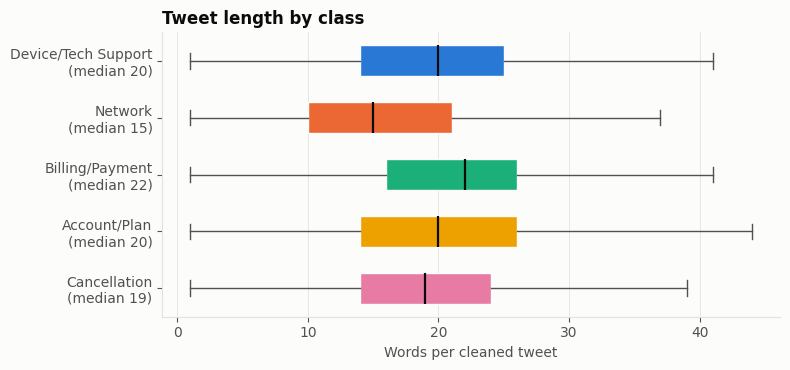

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Device & Technical Support,10387.0,20.7,9.9,1.0,14.0,20.0,25.0,65.0
Network & Connectivity,6085.0,16.5,8.8,1.0,10.0,15.0,21.0,62.0
Billing & Payment,3088.0,22.5,10.1,1.0,16.0,22.0,26.0,62.0
Account & Plan Management,2619.0,21.2,10.2,1.0,14.0,20.0,26.0,61.0
Cancellation & Retention,1749.0,20.0,9.3,1.0,14.0,19.0,24.0,56.0


In [88]:
# Number of words in each cleaned tweet
df_clean["word_count"] = df_clean["text_clean"].str.split().str.len()

# Box plot per class; the median is shown in each axis label
fig, ax = plt.subplots(figsize=(8, 3.8))
data = [df_clean.loc[df_clean["label"] == c, "word_count"] for c in CLASS_ORDER]
bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.55, showfliers=False,
                medianprops={"color": INK, "linewidth": 1.6}, whiskerprops={"color": INK2},
                capprops={"color": INK2})
for patch, c in zip(bp["boxes"], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[c])
    patch.set_edgecolor(SURFACE)
ax.set_yticklabels([f"{SHORT[c]}\n(median {d.median():.0f})" for c, d in zip(CLASS_ORDER, data)])
ax.invert_yaxis()
ax.set_xlabel("Words per cleaned tweet")
ax.grid(axis="y", visible=False)
ax.set_title("Tweet length by class")
plt.tight_layout()
plt.show()

# Summary statistics table
display(df_clean.groupby("label")["word_count"].describe().round(1).loc[CLASS_ORDER])

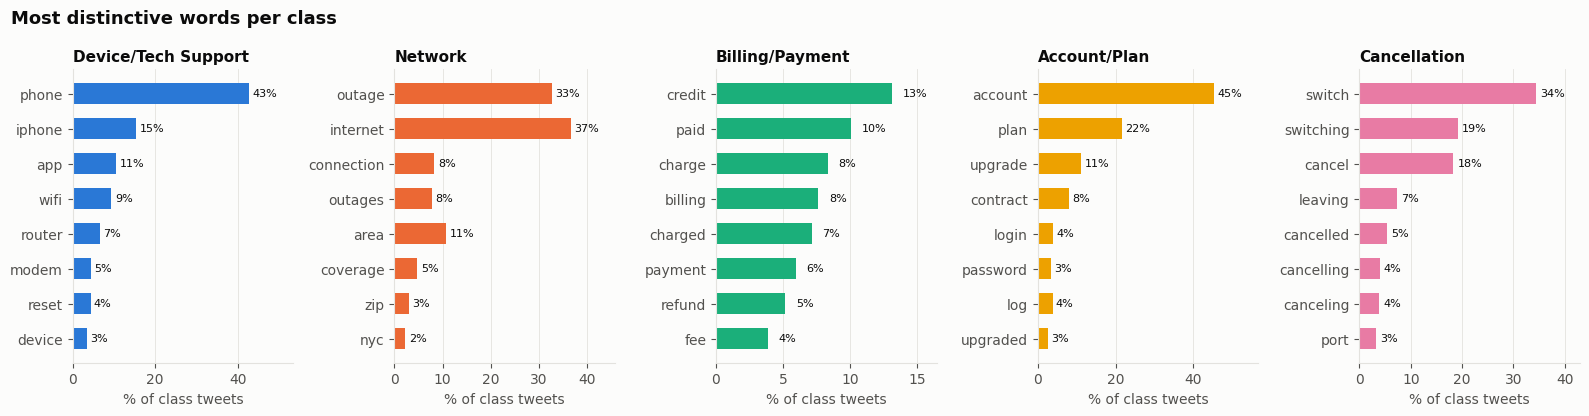

,Device & Technical Support,Network & Connectivity,Billing & Payment,Account & Plan Management,Cancellation & Retention
0,phone,outage,credit,account,switch
1,iphone,internet,paid,plan,switching
2,app,connection,charge,upgrade,cancel
3,wifi,outages,billing,contract,leaving
4,router,area,charged,login,cancelled
5,modem,coverage,payment,password,cancelling
6,reset,zip,refund,log,canceling
7,device,nyc,fee,upgraded,port


In [89]:
# Common filler words to ignore, on top of scikit-learn's English stop word list
STOP = set(ENGLISH_STOP_WORDS) | {
    "im", "ive", "dont", "didnt", "cant", "doesnt", "isnt", "youre", "thats", "thanks", "thank",
    "hi", "hey", "please", "pls", "dm", "just", "like", "get", "got", "know", "need", "want",
    "going", "tried", "try", "amp", "s", "t", "u",
}

# Binary word presence per tweet (a word counts once per tweet); skip words in fewer than 25 tweets
cv = CountVectorizer(binary=True, min_df=25, stop_words=list(STOP))
Xc = cv.fit_transform(df_clean["text_clean"])
terms = np.array(cv.get_feature_names_out())
overall_rate = np.asarray(Xc.mean(axis=0)).ravel()   # share of ALL tweets containing each word

top_terms = {}
fig, axes = plt.subplots(1, 5, figsize=(16, 4.2))
for ax, cls in zip(axes, CLASS_ORDER):
    mask = (df_clean["label"] == cls).values

    # Chi-square: how strongly each word separates this class from all the others
    chi, _ = chi2(Xc, mask.astype(int))
    class_rate = np.asarray(Xc[mask].mean(axis=0)).ravel()

    # Keep only words MORE common in this class than overall, then take the top 8
    score = np.where(class_rate > overall_rate, chi, -np.inf)
    idx = np.argsort(score)[::-1][:8]
    top_terms[cls] = list(terms[idx])

    # Bar length = % of this class's tweets that contain the word
    ax.barh(range(8)[::-1], class_rate[idx] * 100, color=CLASS_COLORS[cls], height=0.62)
    ax.set_yticks(range(8)[::-1])
    ax.set_yticklabels(terms[idx])
    for yi, v in zip(range(8)[::-1], class_rate[idx] * 100):
        ax.text(v + 0.8, yi, f"{v:.0f}%", va="center", color=INK, fontsize=8)
    ax.set_xlim(0, max(class_rate[idx] * 100) * 1.25)
    ax.set_title(SHORT[cls], fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("% of class tweets")
fig.suptitle("Most distinctive words per class", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

display(pd.DataFrame(top_terms))

company
Spectrum    7915
T-Mobile    5743
Verizon     4811
Sprint      3728
AT&T        1731
Name: count, dtype: int64


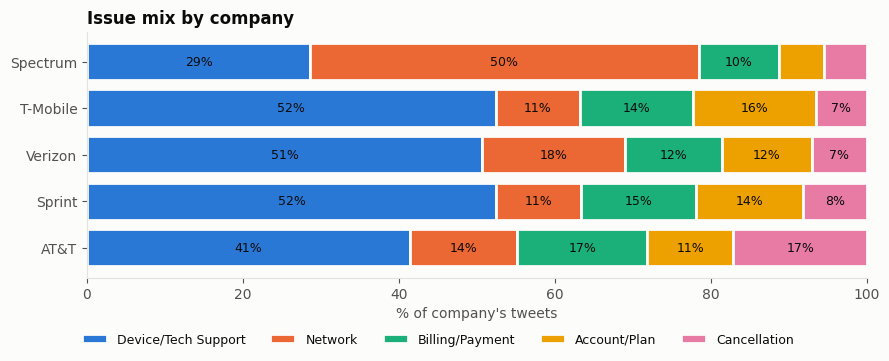

In [90]:
# Map each company's support handle to a company name
HANDLES = {
    "ask_spectrum": "Spectrum", "tmobilehelp": "T-Mobile", "verizonsupport": "Verizon",
    "sprintcare": "Sprint", "att": "AT&T",
}

# Use the first @handle in the original tweet that matches one of the five carriers
def find_company(text):
    for h in re.findall(r"@([A-Za-z_]+)", str(text)):
        if h.lower() in HANDLES:
            return HANDLES[h.lower()]
    return "Unknown"

df_clean["company"] = df_clean["text_original"].map(find_company)
print(df_clean["company"].value_counts())

# For each company, the % of its tweets in each class
known = df_clean[df_clean["company"] != "Unknown"]
share = pd.crosstab(known["company"], known["label"], normalize="index")[CLASS_ORDER] * 100
share = share.loc[known["company"].value_counts().index[::-1]]   # biggest company on top

# 100% stacked bars with a small gap between segments
fig, ax = plt.subplots(figsize=(9, 3.8))
left = np.zeros(len(share))
for c in CLASS_ORDER:
    vals = share[c].values
    ax.barh(share.index, vals, left=left, color=CLASS_COLORS[c], edgecolor=SURFACE, linewidth=2, label=SHORT[c])
    for i, (v, l) in enumerate(zip(vals, left)):
        if v >= 6:   # only label segments wide enough to fit the text
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", color=INK, fontsize=9)
    left += vals
ax.set_xlim(0, 100)
ax.set_xlabel("% of company's tweets")
ax.grid(False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.45, -0.18), frameon=False, fontsize=9)
ax.set_title("Issue mix by company")
plt.tight_layout()
plt.show()

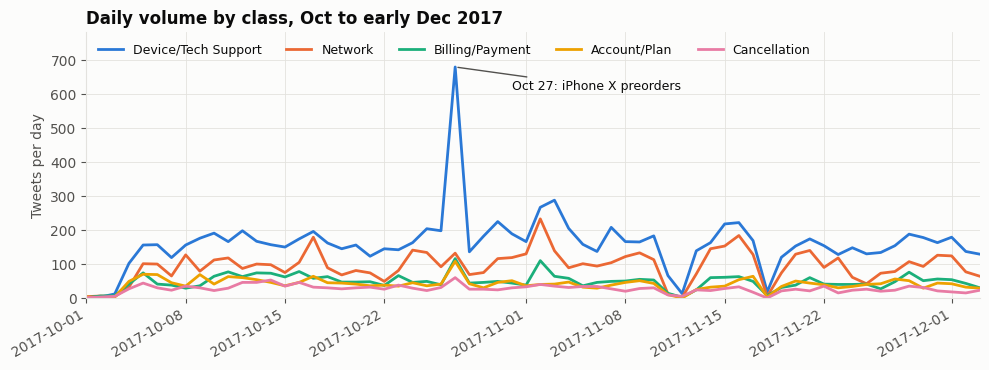

Busiest day: 2017-10-27 1096 tweets


In [91]:
# Parse the timestamp, drop the timezone, and round down to the day
df_clean["date"] = (
    pd.to_datetime(df_clean["created_at"], format="%a %b %d %H:%M:%S %z %Y", errors="coerce")
    .dt.tz_localize(None).dt.normalize()
)

# A handful of rows predate Oct 2017, so start the chart there
recent = df_clean[df_clean["date"] >= "2017-10-01"]
daily = recent.groupby(["date", "label"]).size().unstack(fill_value=0)[CLASS_ORDER]

fig, ax = plt.subplots(figsize=(10, 3.8))
for c in CLASS_ORDER:
    ax.plot(daily.index, daily[c], color=CLASS_COLORS[c], linewidth=2, label=SHORT[c])
ax.set_xlim(daily.index[0], daily.index[-1])
ax.set_ylim(0, daily.values.max() * 1.15)
ax.set_ylabel("Tweets per day")
ax.legend(loc="upper left", ncol=5, frameon=False, fontsize=9)

# Mark the busiest day (Oct 27, 2017 was iPhone X preorder day)
peak = daily.sum(axis=1).idxmax()
ax.annotate(f"{peak:%b %d}: iPhone X preorders", xy=(peak, daily.loc[peak].max()),
            xytext=(peak + pd.Timedelta(days=4), daily.values.max() * 0.9),
            arrowprops={"arrowstyle": "-", "color": INK2}, color=INK, fontsize=9)
ax.set_title("Daily volume by class, Oct to early Dec 2017")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print("Busiest day:", peak.date(), int(daily.sum(axis=1).max()), "tweets")

In [92]:
# Keep the columns the modeling steps need; the response id columns are dropped
cols = ["tweet_id", "company", "date", "text_original", "text_clean", "word_count", "label"]
df_clean[cols].to_csv("twcs_model_ready.csv", index=False)
print("Saved twcs_model_ready.csv", df_clean[cols].shape)

Saved twcs_model_ready.csv (23928, 7)


Task #6 Findings
Network tweets are the shortest (median 15 words); the other classes have medians of 19 to 22 words.
Each class has clear vocabulary: Network is outage, internet and coverage; Billing is credit, paid and charge; Cancellation is switch, cancel and leaving; Account is account, plan and upgrade; Device is phone, iphone, app and router.
Spectrum is the outlier: 50% of its tweets are Network issues, compared with 11% to 18% for the other carriers. AT&T has the highest share of Cancellation tweets at 17%.
Daily volume peaks on Oct 27, 2017 with 1,096 tweets, 680 of them Device & Technical Support, which lines up with iPhone X preorders (mostly T-Mobile and Sprint).

Task #6 Conclusion
The text separates the five classes well, and there is no strong length effect that would need special handling.
The Oct 27 spike will make up a large share of the Device training data, so keep it in mind when reading results.
Repeated tweets (107 after cleaning, with no label conflicts) should be deduplicated before the Task #7 split.

Task #7: Create Train/Validation/Test Datasets
Objective
Split the cleaned data into training, validation and test sets with no overlap between them, using the provided test file as the final held-out set.

In [93]:
# The test file is separate from the training data, so we only apply the SAME cleaning steps to it.
test_url = "https://raw.githubusercontent.com/Break-Through-Tech/Telecom-1A-automated-telecom-support-nlp-agent-for-incident-management/main/data/twcs_labeled_3000_2.csv"
df_test_raw = pd.read_csv(test_url)

print("Test file shape:", df_test_raw.shape)
print("Missing text:", df_test_raw["text"].isna().sum(), "| Missing label:", df_test_raw["label"].isna().sum())

# Same cleaning function used on the training data (Task 4)
df_test = df_test_raw.copy()
df_test["text_original"] = df_test["text"]
df_test["text_clean"] = df_test["text"].map(clean_text)

# Keep only the 5 target classes, as with the training data
df_test = df_test[df_test["label"].isin(TARGET_LABELS)]
df_test = df_test[df_test["text_clean"].str.len() > 0].reset_index(drop=True)

print("Test rows after cleaning:", len(df_test))
display(df_test["label"].value_counts())

Test file shape: (3000, 8)
Missing text: 0 | Missing label: 0
Test rows after cleaning: 3000


,count
label,
Network & Connectivity,600
Billing & Payment,600
Device & Technical Support,600
Account & Plan Management,600
Cancellation & Retention,600


In [94]:
# Identical cleaned text must not appear in both train and validation, or accuracy is inflated.
print("Rows before dedupe:", len(df_clean))

# First make sure repeated text never carries conflicting labels
conflicts = (df_clean.groupby("text_clean")["label"].nunique() > 1).sum()
print("Texts with conflicting labels:", conflicts)

# Keep the first copy of each repeated tweet
df_model = df_clean.drop_duplicates(subset="text_clean", keep="first").reset_index(drop=True)
print("Rows after dedupe:", len(df_model), "| removed:", len(df_clean) - len(df_model))

Rows before dedupe: 23928
Texts with conflicting labels: 0
Rows after dedupe: 23820 | removed: 108


In [95]:
# stratify keeps the class mix identical in both sets; random_state makes the split repeatable.
KEEP_COLS = ["tweet_id", "text_original", "text_clean", "label"]

df_train, df_val = train_test_split(
    df_model[KEEP_COLS],
    test_size=0.20,
    stratify=df_model["label"],
    random_state=42,
)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test[["tweet_id", "text_original", "text_clean", "label"]]

print(f"Train: {len(df_train):,} | Validation: {len(df_val):,} | Test: {len(df_test):,}")

Train: 19,056 | Validation: 4,764 | Test: 3,000


In [96]:
# 1) Class proportions should match between train and validation
split_dist = pd.DataFrame({
    "Train %": (df_train["label"].value_counts(normalize=True) * 100).round(2),
    "Validation %": (df_val["label"].value_counts(normalize=True) * 100).round(2),
    "Test %": (df_test["label"].value_counts(normalize=True) * 100).round(2),
}).reindex(CLASS_ORDER)
display(split_dist)

# 2) No tweet may appear in more than one split (by id and by cleaned text)
train_ids, val_ids, test_ids = (set(d["tweet_id"].astype(str)) for d in (df_train, df_val, df_test))
train_txt, val_txt, test_txt = (set(d["text_clean"]) for d in (df_train, df_val, df_test))

print("tweet_id overlap  train/val:", len(train_ids & val_ids),
      "| train/test:", len(train_ids & test_ids), "| val/test:", len(val_ids & test_ids))
print("text overlap      train/val:", len(train_txt & val_txt),
      "| train/test:", len(train_txt & test_txt), "| val/test:", len(val_txt & test_txt))

# 3) Every split must contain all 5 classes and have no missing values
for name, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    assert d["label"].nunique() == 5, f"{name} is missing a class"
    assert d[["text_clean", "label"]].notna().all().all(), f"{name} has missing values"
print("All checks passed")

,Train %,Validation %,Test %
label,,,
Device & Technical Support,43.46,43.45,20.0
Network & Connectivity,25.37,25.36,20.0
Billing & Payment,12.89,12.89,20.0
Account & Plan Management,10.96,10.98,20.0
Cancellation & Retention,7.32,7.33,20.0


tweet_id overlap  train/val: 0 | train/test: 0 | val/test: 0
text overlap      train/val: 0 | train/test: 0 | val/test: 0
All checks passed


In [97]:
# Validation and test labels must not influence the weights.
# Use these for Logistic Regression and Random Forest (none for Naive Bayes).
weights_dict_train = get_class_weights(df_train["label"])
display(pd.Series(weights_dict_train).reindex(CLASS_ORDER).round(3).rename("Weight"))

,Weight
Device & Technical Support,0.460
Network & Connectivity,0.788
Billing & Payment,1.551
Account & Plan Management,1.824
Cancellation & Retention,2.734


In [98]:
df_train.to_csv("train.csv", index=False)
df_val.to_csv("validation.csv", index=False)
df_test.to_csv("test.csv", index=False)
print("Saved train.csv, validation.csv, test.csv")

from google.colab import files
for name in ["train.csv", "validation.csv", "test.csv"]:
    files.download(name)

Saved train.csv, validation.csv, test.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [99]:
# Sanity check only, not the official model comparison for the October milestone
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = vec.fit_transform(df_train["text_clean"])      # fit on train only
clf = LogisticRegression(max_iter=1000, class_weight=weights_dict_train).fit(X_train, df_train["label"])

rows = []
for name, d in [("Validation", df_val), ("Test", df_test)]:
    pred = clf.predict(vec.transform(d["text_clean"]))
    rows.append({"Split": name,
                 "Accuracy": accuracy_score(d["label"], pred),
                 "Macro F1": f1_score(d["label"], pred, average="macro")})
display(pd.DataFrame(rows).round(3).set_index("Split"))

,Accuracy,Macro F1
Split,,
Validation,0.991,0.989
Test,0.800,0.796


Task #7 Findings
108 repeated tweets were removed from the training data (no repeated text had conflicting labels), leaving 23,820 rows.
The training data was split 80/20 with stratification into 19,056 training rows and 4,764 validation rows. Class shares differ by less than 0.1 percentage points between the two.
The provided 3,000-row test file was cleaned with the same function. It is balanced at 600 tweets per class, unlike the training data, which is 43% Device & Technical Support and 7% Cancellation & Retention.
No tweet ID or cleaned text appears in more than one split.
Class weights were recomputed on the training split only (0.460, 0.788, 1.551, 1.824 and 2.734 from the largest class to the smallest).

Task #7 Conclusion
The datasets are ready for modeling: train.csv, validation.csv and test.csv.
Validation accuracy will likely look much higher than test accuracy because the validation set shares the labeling style and class mix of the training data. Report test results as the main performance number.

## Preprocessing Findings

### Data Filtering
- The raw training file had 76,404 rows. After removing `General / Other` (52,476 rows), 23,928 rows remain across the five target classes.
- The 8 malformed records (non-numeric `tweet_id` such as `#UnhappySpectrumCharterCustomer`, with missing text) all carried the `General / Other` label, so they were removed by the same filter.
- Every remaining row is an inbound customer tweet, so no company replies needed to be filtered out.

### Text Cleaning
- Cleaning decoded HTML entities, removed URLs and @mentions (including numeric ones), lowercased the text, removed punctuation and special characters, and normalized whitespace.
- Apostrophes are removed without inserting a space, so "don't" becomes "dont" and contractions stay as single tokens.
- No tweet became empty after cleaning, and no URL or entity fragments remain. The original text is preserved in `text_original` and the cleaned text is in `text_clean`.
- 90 tweets are one or two words long (for example "WiFi" or "To upgrade"). They were kept because they still carry a clear signal.

### Class Distribution and Imbalance
- Device & Technical Support is the largest class (10,387 tweets, 43.41%) and Cancellation & Retention is the smallest (1,749 tweets, 7.31%), an imbalance of about 5.9 to 1.
- Class weights are preferred over resampling because the imbalance is moderate and weights avoid duplicating or dropping tweets before the split. Weights are applied to Logistic Regression and Random Forest, and not to Naive Bayes, per the project plan.
- Weights computed on the training split only: 0.460 (Device), 0.788 (Network), 1.551 (Billing), 1.824 (Account), 2.734 (Cancellation).

### Duplicates
- 108 tweets repeated an earlier tweet's cleaned text, and none of the repeats had conflicting labels. They were removed, leaving 23,820 rows.
- The training, validation and test sets share no tweet IDs and no cleaned text.

### Final Datasets
- Training: 19,056 rows. Validation: 4,764 rows. Both come from an 80/20 stratified split, and their class shares differ by less than 0.1 percentage points.
- Test: the provided 3,000-row file, cleaned with the same function, with 600 tweets per class.
- The training and validation sets keep the original class imbalance, while the test set is perfectly balanced.

### Label Quality and Dataset Differences
- Between 86% and 96% of each class's tweets contain that class's obvious keywords, which suggests the labels were assigned with keyword rules.
- The test file differs from the training data. It is balanced, its tweets are shorter (median 15 words versus 19), it extends into early 2018, it has no reply-ID values, and 1,390 of its 3,000 cleaned texts are repeats.
- A quick Logistic Regression check reached 99.1% accuracy on validation and 80.0% on the test file. Validation scores are inflated by the shared labeling style, so test results should be reported as the main performance number.

### Conclusion
The data is clean, deduplicated, split without overlap and ready for modeling. Both split quality and class imbalance are handled. The main risks are the keyword-driven labels and the distribution gap between the training data and the test file, so model selection should be judged on test performance, with attention to per-class recall for Network & Connectivity and Cancellation & Retention.